# Obésité, pauvreté et accès aux soins : une analyse par département

Projet de Python pour la data science (ENSAE, 2A).

## Introduction

**Question :** la prévalence de l'obésité d'un territoire est-elle liée à sa pauvreté, à l'accès aux soins (déserts médicaux), à la présence de fast-foods ou à celle de salles de sport ?

**Territoire :** les 96 départements de France métropolitaine.

**Démarche :**
1. présenter les données et la table construite ;
2. décrire les variables (statistiques, distributions, corrélations) ;
3. cartographier l'obésité et ses facteurs possibles ;
4. estimer des régressions pour voir ce qui reste des liens une fois la région prise en compte ;
5. conclure et discuter les limites.

Les résultats décrivent des associations entre départements, pas des causes.

## 1. Données

La table `data/processed/departements.csv` rassemble une ligne par département. Elle est construite par le code de `src/` : `collecte.py` télécharge les sources, `nettoyage.py` les nettoie et les assemble (fonction `table_finale()`). Les fichiers téléchargés sont conservés dans `data/raw/`.

| Variables | Source | Année | Remarque |
|---|---|---|---|
| `obesite`, `obesite_bas`, `obesite_haut` | DREES, enquête EpiCov (vague 2) | octobre-décembre 2020 | part des adultes avec un IMC de 30 ou plus, avec l'intervalle de confiance à 95 % (environ 3 points) ; enquête, probablement déclarative |
| `taux_pauvrete`, `niveau_vie_median` | INSEE, Filosofi | 2021 | taux de pauvreté à 60 % de la médiane, niveau de vie médian en euros |
| `population`, `part_60_plus` | INSEE, estimations de population | 2021 | part des 60 ans et plus calculée à partir des tranches d'âge |
| `densite` | API geo.api.gouv.fr | dernière version | population divisée par la surface des communes du département |
| `apl` | DREES, accessibilité potentielle localisée aux médecins généralistes | 2022 | donnée communale, moyenne départementale pondérée par la population |
| `restauration`, `salles_sport` | INSEE, base permanente des équipements (BPE) | 2025 | restauration (fast-foods compris) et salles de remise en forme |
| `fastfoods` | OpenStreetMap, requête Overpass | extraction du 16 novembre 2026 | points `amenity=fast_food` rattachés aux départements avec leurs contours |
| `region` | API geo.api.gouv.fr | dernière version | région de chaque département |

Les équipements sont ramenés à 10 000 habitants (`restauration_10k`, `salles_sport_10k`, `fastfoods_10k`). Les départements d'outre-mer sont exclus : les contours utilisés ne les couvrent pas, et il manque des données pour certains.

## 2. Chargement

In [19]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [20]:
df = pd.read_csv("../data/processed/departements.csv", dtype={"dep": str, "region": str})
print(df.shape)
print("valeurs manquantes :", df.isna().sum().sum())

(96, 17)
valeurs manquantes : 0


Les codes du département et de la région sont lus comme du texte (`dtype={"dep": str, "region": str}`), sinon `01` deviendrait `1` et `2A` ne serait pas reconnu.

**Constat :** la table contient 96 départements et 17 colonnes, sans aucune valeur manquante.

Les noms des départements et des régions sont ajoutés plus loin à partir de leurs codes.

## 3. Analyse descriptive

### 3.1 Statistiques descriptives

In [21]:
variables = [
    "obesite",
    "taux_pauvrete",
    "niveau_vie_median",
    "apl",
    "restauration_10k",
    "salles_sport_10k",
    "fastfoods_10k",
    "densite",
    "part_60_plus",
]
df[variables].describe().round(1)

,obesite,taux_pauvrete,niveau_vie_median,apl,restauration_10k,salles_sport_10k,fastfoods_10k,densite,part_60_plus
count,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0
mean,15.8,14.9,22706.7,3.6,32.7,1.4,4.3,567.2,29.7
std,3.2,3.0,1721.9,0.6,14.3,0.6,1.6,2398.4,4.8
min,7.8,9.1,19020.0,2.4,18.2,0.6,2.0,14.8,17.5
25%,13.4,12.6,21575.0,3.1,24.0,1.0,3.2,49.6,26.7
50%,16.0,14.8,22285.0,3.6,27.9,1.2,3.9,82.9,29.5
75%,18.0,16.2,23292.5,4.1,37.8,1.5,4.9,164.2,33.4
max,23.3,28.4,29730.0,5.2,98.0,4.9,13.9,19967.5,39.5


**Interprétation :**

- **Obésité :** 15,8 % en moyenne (médiane 16,0 %), avec un écart-type de 3,2 points. Elle va de 7,8 % (Hautes-Alpes) à 23,3 % (Orne), soit plus de 15 points d'écart. Ces valeurs viennent d'une enquête, donc elles ont une marge d'erreur d'environ ±3 points : les départements aux extrémités sont à interpréter avec prudence.
- **Pauvreté :** 14,9 % en moyenne, de 9,1 % (Vendée) à 28,4 % (Seine-Saint-Denis). Les trois quarts des départements sont sous 16,2 %, donc la Seine-Saint-Denis est très au-dessus des autres.
- **Densité :** très asymétrique. La moyenne (567 hab/km²) est bien au-dessus de la médiane (83 hab/km²), parce que Paris dépasse 19 900 hab/km².
- **Fast-foods :** 4,3 pour 10 000 habitants en moyenne, avec un maximum de 13,9 à Paris. La restauration et les salles de sport ont aussi quelques valeurs très élevées.

### 3.2 Distributions

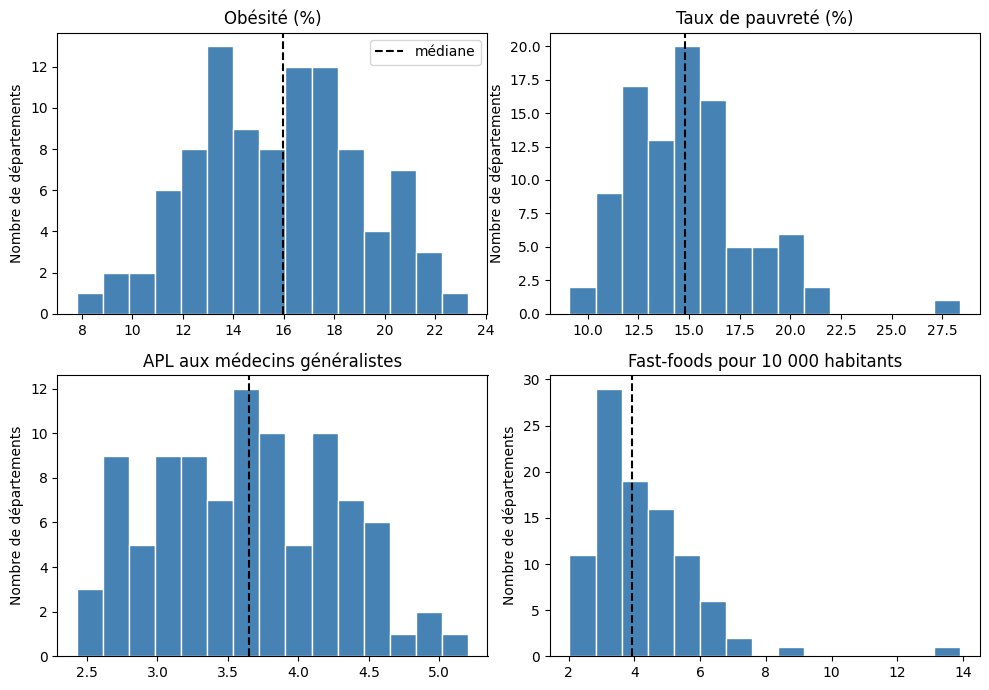

In [22]:
a_tracer = {
    "obesite": "Obésité (%)",
    "taux_pauvrete": "Taux de pauvreté (%)",
    "apl": "APL aux médecins généralistes",
    "fastfoods_10k": "Fast-foods pour 10 000 habitants",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (colonne, titre) in zip(axes.flat, a_tracer.items()):
    ax.hist(df[colonne], bins=15, color="steelblue", edgecolor="white")
    ax.axvline(df[colonne].median(), color="black", linestyle="--", label="médiane")
    ax.set_title(titre)
    ax.set_ylabel("Nombre de départements")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Interprétation :**

- **Obésité :** la distribution est assez symétrique, centrée autour de 16 %, sans valeur isolée. La plupart des départements sont entre 12 % et 20 %.
- **Pauvreté :** la plupart des départements sont entre 10 % et 20 %. La distribution s'étire vers la droite et un département est isolé autour de 28 % (la Seine-Saint-Denis).
- **APL :** les valeurs sont réparties de façon assez régulière entre 2,4 et 5,2, sans valeur extrême.
- **Fast-foods :** la distribution est très asymétrique. La plupart des départements ont entre 2 et 6 fast-foods pour 10 000 habitants, et quelques-uns sont très au-dessus, dont Paris à 13,9.

### 3.3 Départements extrêmes

In [23]:
with open("../data/raw/departements.geojson", encoding="utf-8") as f:
    contours = json.load(f)
noms = {d["properties"]["code"]: d["properties"]["nom"] for d in contours["features"]}
df["nom"] = df["dep"].map(noms)

colonnes = ["nom", "obesite", "taux_pauvrete", "apl", "fastfoods_10k"]
df.sort_values("obesite", ascending=False)[colonnes].head(5).round(1)

,nom,obesite,taux_pauvrete,apl,fastfoods_10k
58,Orne,23.3,15.6,2.9,3.2
59,Pas-de-Calais,21.9,18.4,4.3,3.6
78,Ardennes,21.7,19.4,3.7,3.4
11,Aisne,21.4,18.8,3.2,2.7
30,Indre,21.2,15.4,2.8,3.3


In [24]:
df.sort_values("obesite")[colonnes].head(5).round(1)

,nom,obesite,taux_pauvrete,apl,fastfoods_10k
45,Hautes-Alpes,7.8,14.7,5.2,8.9
21,Corse-du-Sud,9.0,15.8,3.9,5.4
73,Paris,9.1,15.6,4.7,13.9
29,Ille-et-Vilaine,10.5,10.8,4.1,3.6
22,Haute-Corse,10.8,20.2,3.8,5.9


**Interprétation :**

- **Les plus touchés :** l'Orne (23,3 %), le Pas-de-Calais, les Ardennes, l'Aisne et l'Indre. Ce sont des départements du nord, de l'est et du centre, plutôt ruraux. Leur taux de pauvreté est variable (de 15,4 % à 19,4 %), mais leur nombre de fast-foods est faible (entre 2,7 et 3,6 pour 10 000 habitants).
- **Les moins touchés :** les Hautes-Alpes (7,8 %), la Corse-du-Sud, Paris, l'Ille-et-Vilaine et la Haute-Corse. Ce sont des départements touristiques, très urbains ou aisés, et plusieurs ont beaucoup de fast-foods (Paris 13,9 et Hautes-Alpes 8,9).
- Les départements où il y a le plus de fast-foods ne sont donc pas ceux où l'obésité est la plus forte. Cela ne veut pas dire que les fast-foods protègent : ces départements ont d'autres points communs (tourisme, population jeune ou aisée).

### 3.4 Corrélations

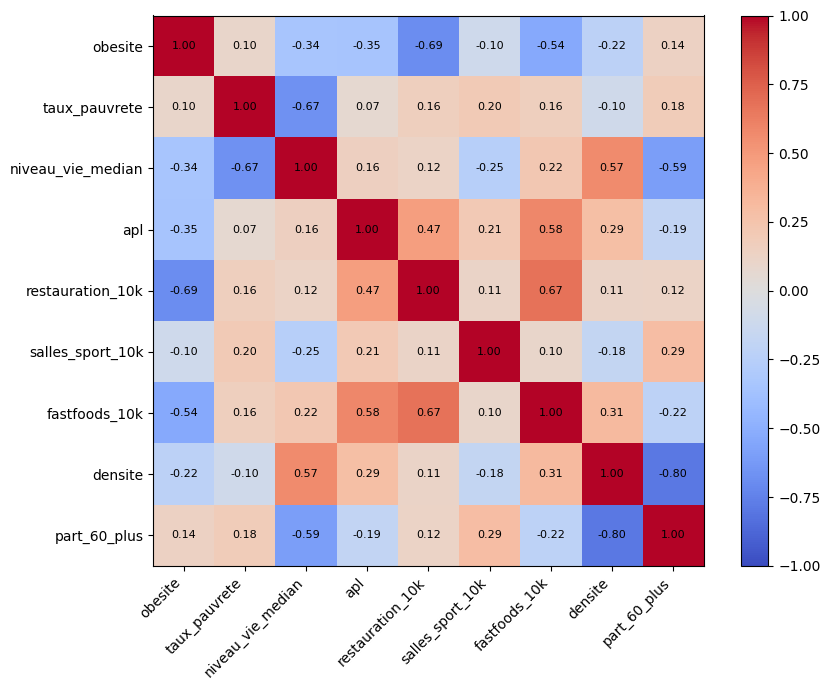

In [25]:
correlations = df[variables].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)))
ax.set_xticklabels(variables, rotation=45, ha="right")
ax.set_yticks(range(len(variables)))
ax.set_yticklabels(variables)
for i in range(len(variables)):
    for j in range(len(variables)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image)
plt.tight_layout()
plt.show()

**Interprétation :**

- **Pauvreté et obésité :** la corrélation est quasi nulle (0,10). Au niveau des départements, la pauvreté seule n'explique pas l'obésité. Le niveau de vie médian est un peu plus lié (-0,34).
- **Accès aux médecins :** l'APL est faiblement négative avec l'obésité (-0,35) : un meilleur accès aux médecins va avec un peu moins d'obésité.
- **Restauration et fast-foods :** ce sont les corrélations les plus fortes avec l'obésité, mais négatives (-0,69 et -0,54). Les départements avec le plus de restaurants et de fast-foods ont moins d'obésité, ce qui rejoint ce qu'on a vu avec les départements extrêmes (tourisme, villes). Ce n'est pas un effet des fast-foods eux-mêmes.
- **Salles de sport :** pas de lien net (-0,10).
- **Liens entre variables explicatives :** certaines se ressemblent beaucoup. La densité et la part des 60 ans et plus (-0,80), la pauvreté et le niveau de vie (-0,67), la restauration et les fast-foods (0,67, normal car les fast-foods sont comptés dans la restauration). Il faudra s'en méfier dans la régression, car deux variables très liées sont difficiles à séparer.

Ces corrélations montrent des liens, pas des causes.

### 3.5 Nuages de points

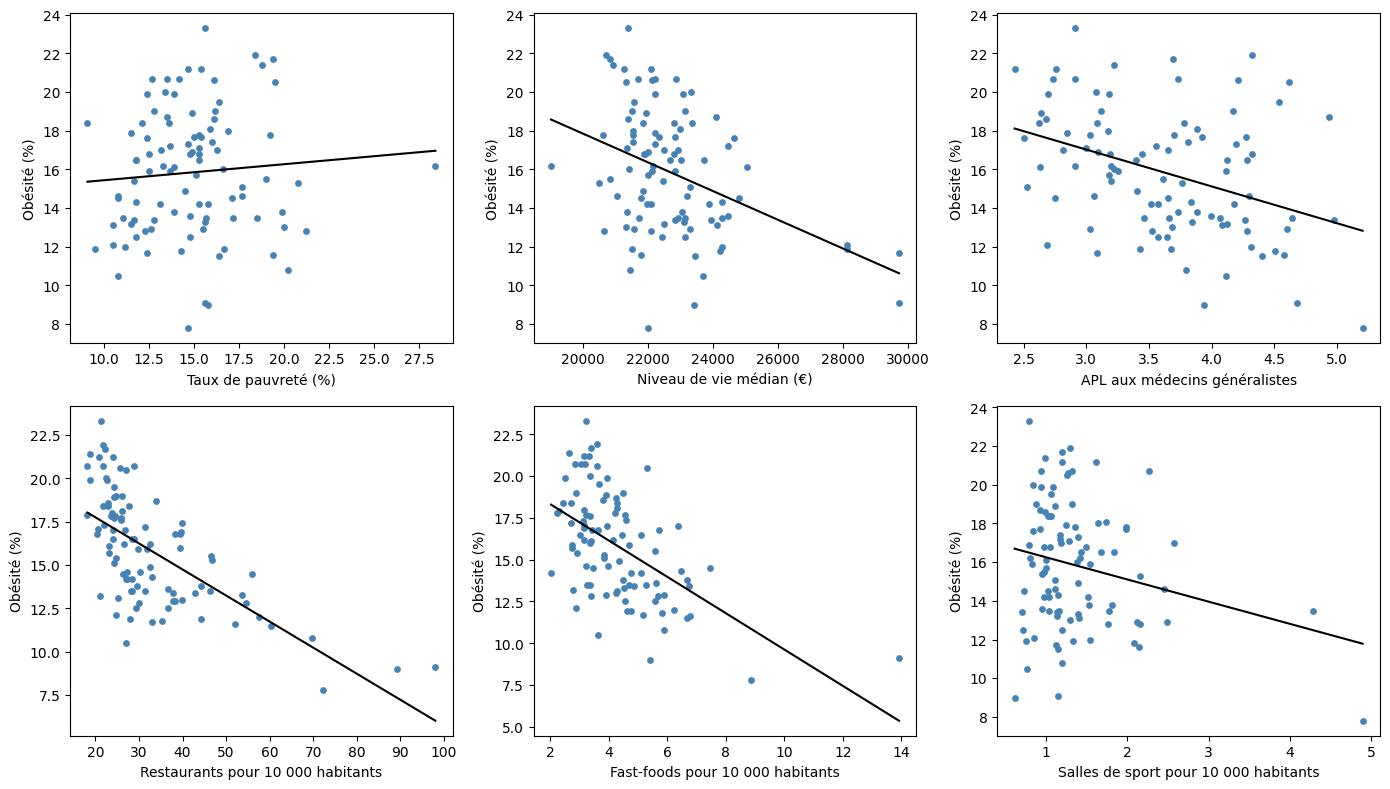

In [26]:
explicatives = {
    "taux_pauvrete": "Taux de pauvreté (%)",
    "niveau_vie_median": "Niveau de vie médian (€)",
    "apl": "APL aux médecins généralistes",
    "restauration_10k": "Restaurants pour 10 000 habitants",
    "fastfoods_10k": "Fast-foods pour 10 000 habitants",
    "salles_sport_10k": "Salles de sport pour 10 000 habitants",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (colonne, titre) in zip(axes.flat, explicatives.items()):
    ax.scatter(df[colonne], df["obesite"], s=15, color="steelblue")
    pente, origine = np.polyfit(df[colonne], df["obesite"], 1)
    x = np.linspace(df[colonne].min(), df[colonne].max(), 100)
    ax.plot(x, pente * x + origine, color="black")
    ax.set_xlabel(titre)
    ax.set_ylabel("Obésité (%)")
plt.tight_layout()
plt.show()

**Interprétation :**

- **Pauvreté :** le nuage n'a pas de forme et la droite est presque plate. À ce niveau, la pauvreté seule n'explique pas l'obésité.
- **Niveau de vie et APL :** les droites descendent, mais les points sont très dispersés. Pour le niveau de vie, la pente vient en partie de quelques départements très aisés, tout à droite du graphique.
- **Restauration et fast-foods :** la relation est nettement négative. Elle est portée en partie par quelques points isolés (beaucoup de restaurants, peu d'obésité), ce qui correspond à Paris, à la Corse et aux Hautes-Alpes vus plus haut.
- **Salles de sport :** les points sont dispersés et la droite dépend surtout d'un point isolé à droite.

Une droite sur un nuage ne tient pas compte des autres variables : c'est le rôle de la régression de les séparer.

### 3.6 Obésité par région

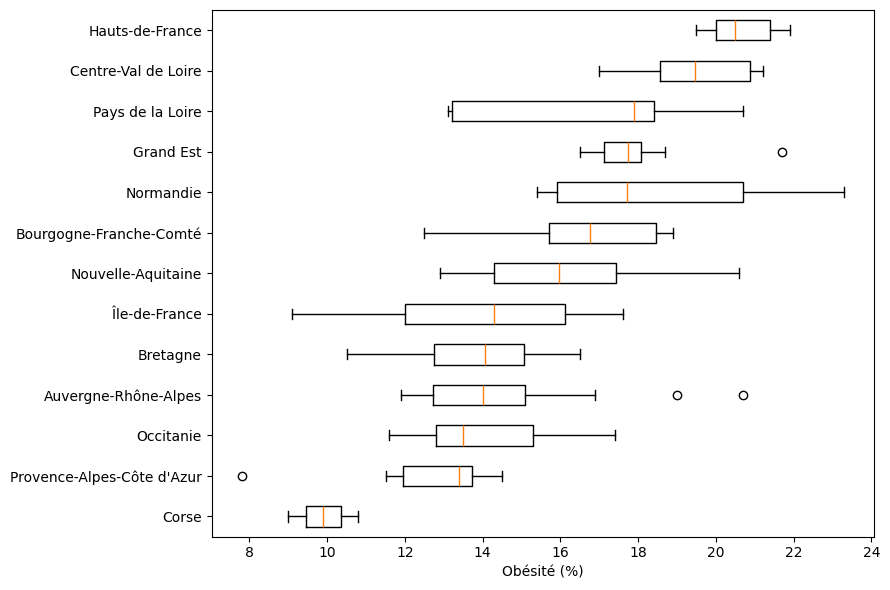

In [27]:
noms_regions = {
    "11": "Île-de-France",
    "24": "Centre-Val de Loire",
    "27": "Bourgogne-Franche-Comté",
    "28": "Normandie",
    "32": "Hauts-de-France",
    "44": "Grand Est",
    "52": "Pays de la Loire",
    "53": "Bretagne",
    "75": "Nouvelle-Aquitaine",
    "76": "Occitanie",
    "84": "Auvergne-Rhône-Alpes",
    "93": "Provence-Alpes-Côte d'Azur",
    "94": "Corse",
}
df["nom_region"] = df["region"].map(noms_regions)

ordre = df.groupby("nom_region")["obesite"].median().sort_values().index
donnees = [df.loc[df["nom_region"] == r, "obesite"] for r in ordre]

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(donnees, vert=False)
ax.set_yticklabels(ordre)
ax.set_xlabel("Obésité (%)")
plt.tight_layout()
plt.show()

**Interprétation :** la région compte beaucoup. L'obésité médiane va de 9,9 % en Corse et 13,4 % en Provence-Alpes-Côte d'Azur à 20,5 % dans les Hauts-de-France, et plusieurs régions du nord et du centre (Centre-Val de Loire, Pays de la Loire, Normandie, Grand Est) ont une médiane autour de 18 % ou plus. Les écarts entre régions sont importants, et à l'intérieur d'une même région les départements sont souvent assez proches.

Les régions ne sont pas ordonnées de la même façon pour la pauvreté et pour l'obésité. La Corse, Provence-Alpes-Côte d'Azur et l'Occitanie ont une pauvreté élevée mais peu d'obésité, alors que la Bretagne et les Pays de la Loire ont une pauvreté faible. Ces différences entre régions peuvent masquer un lien entre pauvreté et obésité à l'intérieur de chaque région.

### 3.7 Ce qu'on retient

- La table est complète : 96 départements, aucune valeur manquante.
- L'obésité varie beaucoup entre départements (de 7,8 % à 23,3 %), avec une distribution assez symétrique.
- La pauvreté seule n'est presque pas liée à l'obésité (corrélation de 0,10).
- Les fast-foods et la restauration sont liés négativement à l'obésité, ce qui vient du profil des territoires (villes, tourisme) et non d'un effet protecteur.
- La région explique une grande part des écarts d'obésité.
- Plusieurs variables explicatives sont très liées entre elles (densité et part des 60 ans et plus, pauvreté et niveau de vie, restauration et fast-foods).

Ces constats posent la question suivante pour la régression : que reste-t-il des liens une fois la région prise en compte ?